In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [2]:
df = pd.read_excel("Practical_Dataset for ML.xlsx", sheet_name="Data")

print("Dataset Shape:", df.shape)
df.head()

Dataset Shape: (3000, 17)


,house_id,size_sqm,num_bedrooms,num_bathrooms,floor_level,age_years,renovated,distance_to_bole_km,distance_to_main_road_m,has_garage,parking_spaces,has_garden,security_service,water_supply_hours_per_day,school_rating,days_on_market,price_etb
0,AA-10000,84.8,3,3,0,12,1,9.54,195,1,1,0,1,18.1,4.2,56,4664000
1,AA-10001,142.1,4,3,12,21,0,2.03,119,1,3,0,1,9.1,6.1,19,6209000
2,AA-10002,110.3,3,3,0,6,0,6.96,260,0,0,1,0,24.0,6.7,19,5804000
3,AA-10003,32.0,1,1,11,5,0,7.28,157,0,0,0,0,13.5,4.6,74,1134000
4,AA-10004,61.9,2,1,6,13,0,10.04,153,1,2,0,1,18.1,7.5,12,1810000


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 17 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   house_id                    3000 non-null   str    
 1   size_sqm                    3000 non-null   float64
 2   num_bedrooms                3000 non-null   int64  
 3   num_bathrooms               3000 non-null   int64  
 4   floor_level                 3000 non-null   int64  
 5   age_years                   3000 non-null   int64  
 6   renovated                   3000 non-null   int64  
 7   distance_to_bole_km         3000 non-null   float64
 8   distance_to_main_road_m     3000 non-null   int64  
 9   has_garage                  3000 non-null   int64  
 10  parking_spaces              3000 non-null   int64  
 11  has_garden                  3000 non-null   int64  
 12  security_service            3000 non-null   int64  
 13  water_supply_hours_per_day  2937 non-null   

In [4]:
df.describe()

,size_sqm,num_bedrooms,num_bathrooms,floor_level,age_years,renovated,distance_to_bole_km,distance_to_main_road_m,has_garage,parking_spaces,has_garden,security_service,water_supply_hours_per_day,school_rating,days_on_market,price_etb
count,3000.000000,3000.000000,3000.000000,3000.00000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,2937.000000,2947.000000,3000.000000,3.000000e+03
mean,140.666033,3.939667,3.396000,4.14800,8.951667,0.166667,8.365070,219.174333,0.453667,0.906333,0.283333,0.370333,14.831324,6.287038,45.348000,6.000234e+06
std,90.250804,1.917790,1.772446,4.86237,8.684458,0.372740,4.886192,218.510644,0.497932,1.136071,0.450692,0.482974,5.212496,1.742851,45.011542,4.914972e+06
min,32.000000,1.000000,1.000000,0.00000,0.000000,0.000000,0.300000,10.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,5.560000e+05
25%,79.800000,2.000000,2.000000,0.00000,3.000000,0.000000,4.617500,62.000000,0.000000,0.000000,0.000000,0.000000,11.300000,5.100000,13.000000,2.872500e+06
50%,111.100000,4.000000,3.000000,2.00000,6.000000,0.000000,8.130000,152.000000,0.000000,0.000000,0.000000,0.000000,14.800000,6.300000,32.000000,4.378000e+06
75%,176.625000,5.000000,5.000000,8.00000,12.000000,0.000000,11.650000,309.000000,1.000000,2.000000,1.000000,1.000000,18.600000,7.500000,63.000000,7.321500e+06
max,572.400000,7.000000,6.000000,14.00000,45.000000,1.000000,23.370000,2087.000000,1.000000,3.000000,1.000000,1.000000,24.000000,10.000000,375.000000,4.097300e+07


In [5]:
df.isnull().sum()

house_id                       0
size_sqm                       0
num_bedrooms                   0
num_bathrooms                  0
floor_level                    0
age_years                      0
renovated                      0
distance_to_bole_km            0
distance_to_main_road_m        0
has_garage                     0
parking_spaces                 0
has_garden                     0
security_service               0
water_supply_hours_per_day    63
school_rating                 53
days_on_market                 0
price_etb                      0
dtype: int64

In [6]:
X = df[["size_sqm"]]
y = df["price_etb"]

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [8]:
model = LinearRegression()

model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[47363.05]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['size_sqm']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-6.783e+05
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


In [9]:
y_pred = model.predict(X_test)

print("Predictions:")
print(y_pred[:10])

Predictions:
[4100676.29106658 2949754.2588384  2324562.04380086 6426201.87881984
 7392408.02933239 5677865.74263854 4830067.20861037 3257614.06169779
 3096579.70327903 3233932.53840091]


In [10]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R²:", r2)

MAE: 1603658.8719095672
MSE: 6987125708692.34
RMSE: 2643317.178980294
R²: 0.7387926337321777


In [11]:
print("Intercept:", model.intercept_)
print("Slope:", model.coef_[0])

print(
    f"Regression Equation: price_etb = "
    f"{model.intercept_:.2f} + "
    f"{model.coef_[0]:.2f} × size_sqm"
)

Intercept: -678255.1102430504
Slope: 47363.04659375257
Regression Equation: price_etb = -678255.11 + 47363.05 × size_sqm


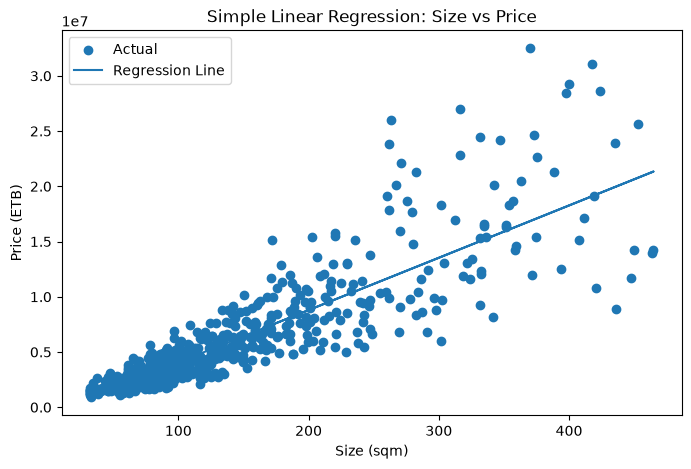

In [12]:
plt.figure(figsize=(8, 5))

plt.scatter(
    X_test["size_sqm"],
    y_test,
    label="Actual"
)

plt.plot(
    X_test["size_sqm"],
    y_pred,
    label="Regression Line"
)

plt.xlabel("Size (sqm)")
plt.ylabel("Price (ETB)")
plt.title("Simple Linear Regression: Size vs Price")
plt.legend()
plt.show()